# Task 14 — Final Industry-Style Data Analytics Project

**Business Problem:** 
Superstore generates $2.3M in sales but only a 12.47% profit margin. 
Why is profit low, and where should leadership focus to improve it?

**Dataset:** Sample Superstore (9,994 rows, 21 columns)
**Tools:** Python (Pandas, Matplotlib, Seaborn), SQL (SQLite), Power BI
**Analyst:** Sathwik Soma

In [1]:
# Step 1: Import libraries and load data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print("=== DATA CLEANING STARTED ===")

# Load raw data
df = pd.read_csv("SampleSuperstore.csv", encoding="latin1")
print(f"Original shape: {df.shape}")

# 1. Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)

# 2. Fix Date Types (DD-MM-YYYY -> Datetime)
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%d-%m-%Y', errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%d-%m-%Y', errors='coerce')

# 3. Handle nulls
df = df.dropna(subset=['Sales', 'Profit', 'Order Date'])

# 4. Create new useful columns for analysis
# NOTE: We use strftime here so SQLite can read it as text!
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['YearMonth'] = df['Order Date'].dt.strftime('%Y-%m')

print(f"Cleaned shape: {df.shape}")
print(f"Missing values remaining: {df.isnull().sum().sum()}")
print(f"Date range: {df['Order Date'].min().date()} to {df['Order Date'].max().date()}")

=== DATA CLEANING STARTED ===
Original shape: (9994, 21)
Cleaned shape: (9994, 24)
Missing values remaining: 0
Date range: 2011-01-04 to 2014-12-31


In [2]:
# Step 2: SQL Analysis using SQLite
conn = sqlite3.connect(":memory:")
df.to_sql("superstore", conn, index=False, if_exists="replace")

print("=== SQL ANALYSIS ===")

q1 = """
SELECT 
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin_Pct
FROM superstore;
"""
print("\n1. Overall Performance:")
print(pd.read_sql(q1, conn).to_string(index=False))

q2 = """
SELECT Region, ROUND(SUM(Sales), 2) AS Sales, ROUND(SUM(Profit), 2) AS Profit
FROM superstore GROUP BY Region ORDER BY Sales DESC;
"""
print("\n2. Regional Performance:")
print(pd.read_sql(q2, conn).to_string(index=False))

q3 = """
SELECT "Sub-Category", ROUND(SUM(Profit), 2) AS Total_Profit
FROM superstore GROUP BY "Sub-Category" HAVING SUM(Profit) < 0 ORDER BY Total_Profit ASC;
"""
print("\n3. Loss-Making Sub-Categories:")
print(pd.read_sql(q3, conn).to_string(index=False))

=== SQL ANALYSIS ===

1. Overall Performance:
 Total_Sales  Total_Profit  Profit_Margin_Pct
  2297200.86     286397.02              12.47

2. Regional Performance:
 Region     Sales    Profit
   West 725457.82 108418.45
   East 678781.24  91522.78
Central 501239.89  39706.36
  South 391721.91  46749.43

3. Loss-Making Sub-Categories:
Sub-Category  Total_Profit
      Tables     -17725.48
   Bookcases      -3472.56
    Supplies      -1189.10


Generating EDA charts...


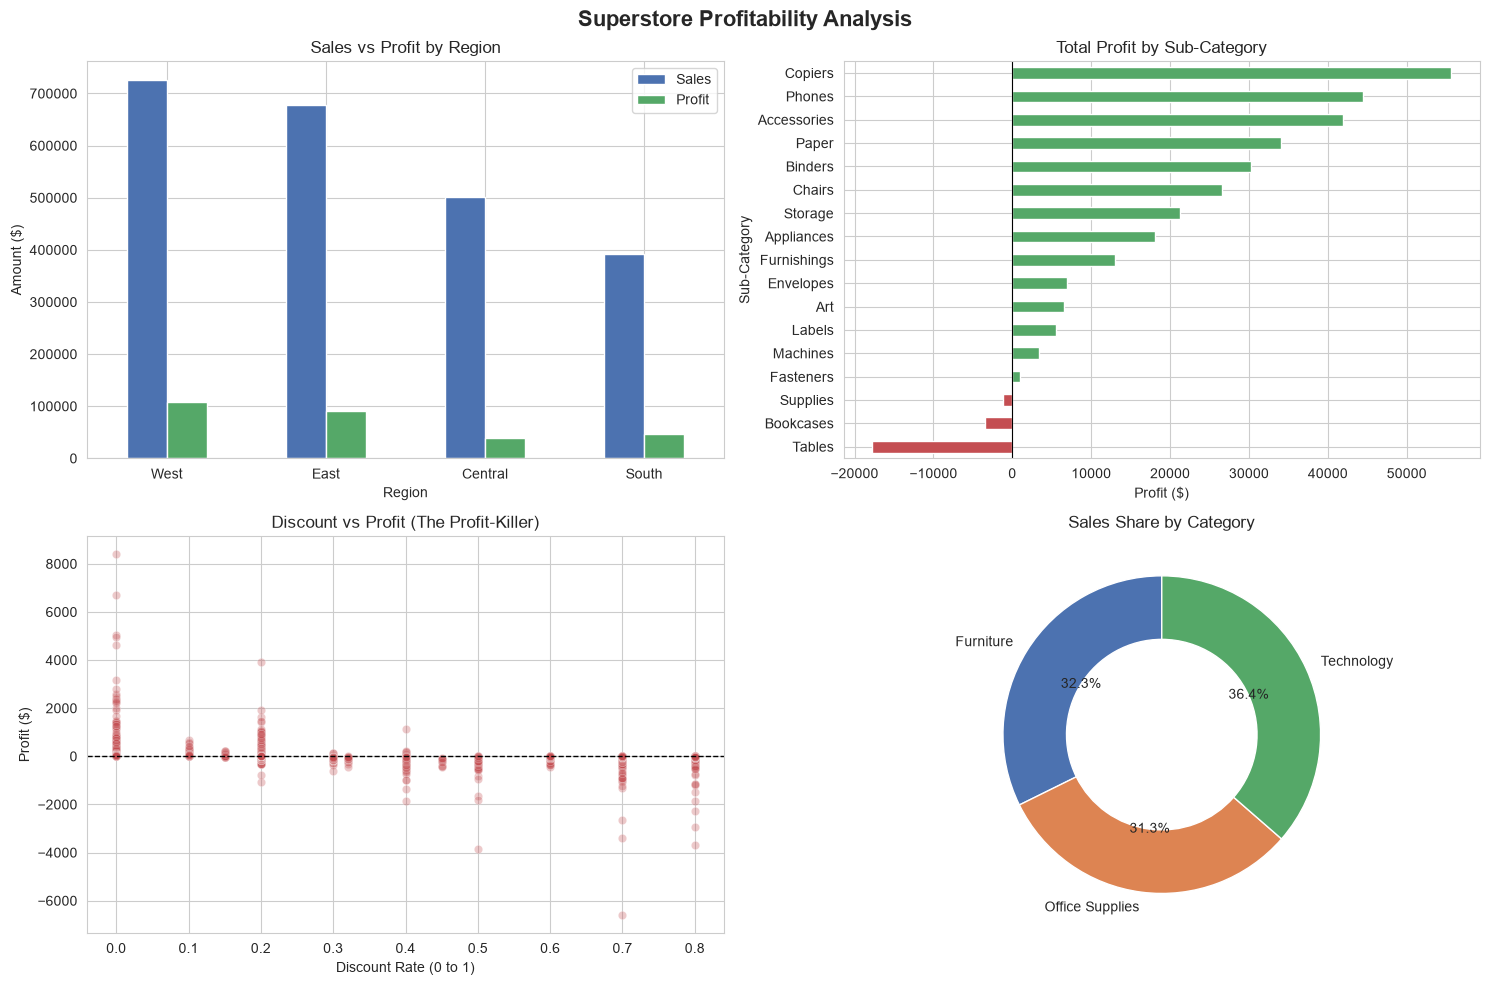

Charts generated successfully!


In [3]:
# Step 3: Exploratory Data Analysis (Charts)
print("Generating EDA charts...")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Superstore Profitability Analysis', fontsize=16, fontweight='bold')

# 1. Sales vs Profit by Region (Bar chart)
region_stats = df.groupby('Region')[['Sales', 'Profit']].sum().sort_values('Sales', ascending=False)
region_stats.plot(kind='bar', ax=axes[0, 0], color=['#4C72B0', '#55A868'])
axes[0, 0].set_title('Sales vs Profit by Region')
axes[0, 0].set_ylabel('Amount ($)')
axes[0, 0].tick_params(axis='x', rotation=0)

# 2. Profit by Sub-Category (Horizontal Bar, sorted)
subcat_profit = df.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=True)
colors = ['#C44E52' if x < 0 else '#55A868' for x in subcat_profit]
subcat_profit.plot(kind='barh', ax=axes[0, 1], color=colors)
axes[0, 1].set_title('Total Profit by Sub-Category')
axes[0, 1].axvline(0, color='black', linewidth=0.8)
axes[0, 1].set_xlabel('Profit ($)')

# 3. The Discount Problem (Scatter Plot)
sns.scatterplot(data=df, x='Discount', y='Profit', alpha=0.3, ax=axes[1, 0], color='#C44E52')
axes[1, 0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1, 0].set_title('Discount vs Profit (The Profit-Killer)')
axes[1, 0].set_xlabel('Discount Rate (0 to 1)')
axes[1, 0].set_ylabel('Profit ($)')

# 4. Sales by Category (Donut Chart)
cat_sales = df.groupby('Category')['Sales'].sum()
axes[1, 1].pie(cat_sales, labels=cat_sales.index, autopct='%1.1f%%', 
               colors=['#4C72B0', '#DD8452', '#55A868'], startangle=90, 
               wedgeprops=dict(width=0.4, edgecolor='white'))
axes[1, 1].set_title('Sales Share by Category')

plt.tight_layout()
plt.show()

print("Charts generated successfully!")

In [4]:
# Step 4: Statistical Analysis
from scipy import stats

print("=== STATISTICAL ANALYSIS ===")

# Test 1: Does discounting significantly reduce profit?
discounted = df[df['Discount'] > 0]['Profit']
full_price = df[df['Discount'] == 0]['Profit']

t_stat, p_value = stats.ttest_ind(discounted, full_price, equal_var=False)
print(f"\n1. T-Test: Discounted vs Full-Price Orders")
print(f"   Average Profit (Full Price): ${full_price.mean():.2f}")
print(f"   Average Profit (Discounted): ${discounted.mean():.2f}")
print(f"   P-value: {p_value:.5f}")
if p_value < 0.05:
    print("   Result: Statistically SIGNIFICANT. Discounts destroy profit.")

# Test 2: Are regional profits significantly different? (ANOVA)
regions = [group['Profit'].values for name, group in df.groupby('Region')]
f_stat, p_value_anova = stats.f_oneway(*regions)
print(f"\n2. ANOVA: Profit across 4 Regions")
print(f"   P-value: {p_value_anova:.5f}")
if p_value_anova < 0.05:
    print("   Result: Statistically SIGNIFICANT. Regional performance varies.")

=== STATISTICAL ANALYSIS ===

1. T-Test: Discounted vs Full-Price Orders
   Average Profit (Full Price): $66.90
   Average Profit (Discounted): $-6.66
   P-value: 0.00000
   Result: Statistically SIGNIFICANT. Discounts destroy profit.

2. ANOVA: Profit across 4 Regions
   P-value: 0.04889
   Result: Statistically SIGNIFICANT. Regional performance varies.


## Final Business Insights & Recommendations

### The Problem
While Superstore generated **$2.29M** in sales, the overall profit margin is only **12.47%**. 

### Root Causes Identified
1. **The Discount Trap:** Statistical testing proves that discounts >20% drastically reduce profit. Orders with high discounts often result in a net loss.
2. **Loss-Making Products:** Furniture sub-categories like **Tables (-$17.7K)** and **Bookcases (-$3.4K)** are actively losing money, likely due to aggressive discounting to move inventory.
3. **Regional Imbalance:** The **Central** region has a profit margin of only **7.9%**, which is half of the **West** region's margin (**14.9%**).

### Strategic Recommendations
1. **Cap Discounts at 20%:** Implement a strict approval process for any discount above 20%. The data proves this is the threshold where profit turns negative.
2. **Discontinue or Reprice Tables & Bookcases:** Stop selling these products at a loss. Either renegotiate supplier costs or remove them from the catalog.
3. **Investigate the Central Region:** The Central region is underperforming. Leadership needs to audit the sales strategies and discounting habits of the Central sales team.
4. **Focus on Technology:** The Technology category (especially Copiers and Phones) is the highest profit driver. Shift marketing focus to these items.